# TP4 Retail Intelligence

Analyse UC08 des jeux Silver et Gold produits dans l’UC06. Les champs sont techniques et les limites métier sont documentées dans `docs/`.

In [1]:
from pyspark.sql import SparkSession, functions as F
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

spark = (SparkSession.builder.master('local[2]').appName('TP4-Retail-Intelligence').getOrCreate())
spark.sparkContext.setLogLevel('WARN')
silver = spark.read.parquet('/opt/project/output/data/silver/promotion')
gold = spark.read.parquet('/opt/project/output/data/gold/promotion_summary')
out = Path('/opt/project/tp4/analytics')
(out / 'outputs').mkdir(parents=True, exist_ok=True)
(out / 'visualizations').mkdir(parents=True, exist_ok=True)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/19 10:59:58 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
                                                                                

In [2]:
print('Silver lignes :', silver.count())
print('Silver colonnes :', len(silver.columns))
print('Gold lignes :', gold.count())
print('Catégories Gold :', gold.select('field_07').distinct().count())
silver.printSchema()
gold.show(truncate=False)

Silver lignes : 300
Silver colonnes : 19
Gold lignes : 9


Catégories Gold : 9
root
 |-- field_00: integer (nullable = true)
 |-- field_01: string (nullable = true)
 |-- field_02: integer (nullable = true)
 |-- field_03: integer (nullable = true)
 |-- field_04: integer (nullable = true)
 |-- field_05: decimal(12,2) (nullable = true)
 |-- field_06: string (nullable = true)
 |-- field_07: string (nullable = true)
 |-- field_08: string (nullable = true)
 |-- field_09: string (nullable = true)
 |-- field_10: string (nullable = true)
 |-- field_11: string (nullable = true)
 |-- field_12: string (nullable = true)
 |-- field_13: string (nullable = true)
 |-- field_14: string (nullable = true)
 |-- field_15: string (nullable = true)
 |-- field_16: string (nullable = true)
 |-- field_17: string (nullable = true)
 |-- field_18: string (nullable = true)

+--------+---------------+------------+
|field_07|promotion_count|average_cost|
+--------+---------------+------------+
|anti    |36             |564.18      |
|pri     |35             |577.82      |
|ou

In [3]:
stats = silver.select(
    F.count('*').alias('silver_rows'),
    F.min('field_05').alias('field_05_min'),
    F.max('field_05').alias('field_05_max'),
    F.round(F.avg('field_05'), 2).alias('field_05_average'),
    F.expr('percentile_approx(field_05, 0.5)').alias('field_05_median')
).toPandas()
stats.to_csv(out / 'outputs/statistiques.csv', index=False)
stats

/opt/spark/python/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,silver_rows,field_05_min,field_05_max,field_05_average,field_05_median
0,300,12.63,995.16,521.23,559.51


In [4]:
by_category = gold.orderBy(F.desc('promotion_count')).toPandas()
by_category.to_csv(out / 'outputs/kpi_par_categorie.csv', index=False)
by_category

/opt/spark/python/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,field_07,promotion_count,average_cost
0,able,37,446.43
1,anti,36,564.18
2,ation,36,530.95
3,pri,35,577.82
4,bar,33,517.13
5,cally,33,545.79
6,ought,32,597.34
7,eing,31,514.89
8,ese,27,372.26


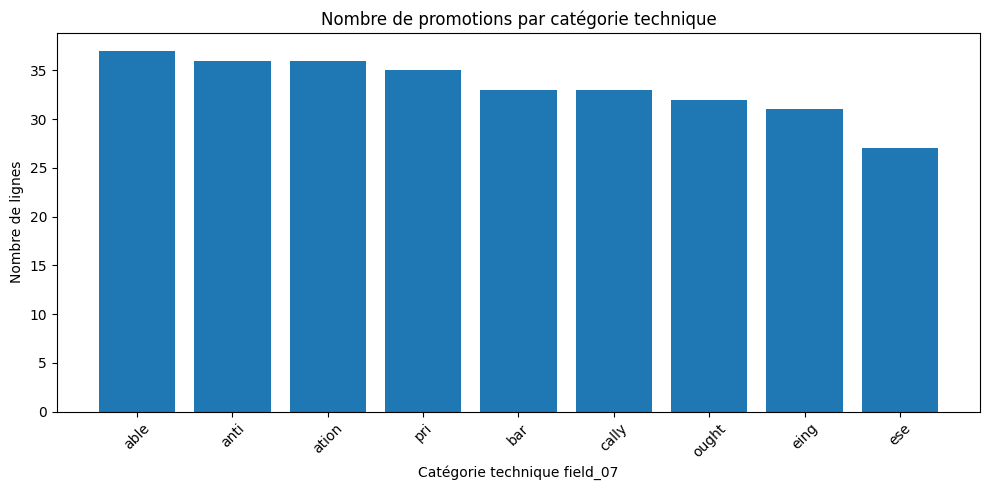

/opt/spark/python/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


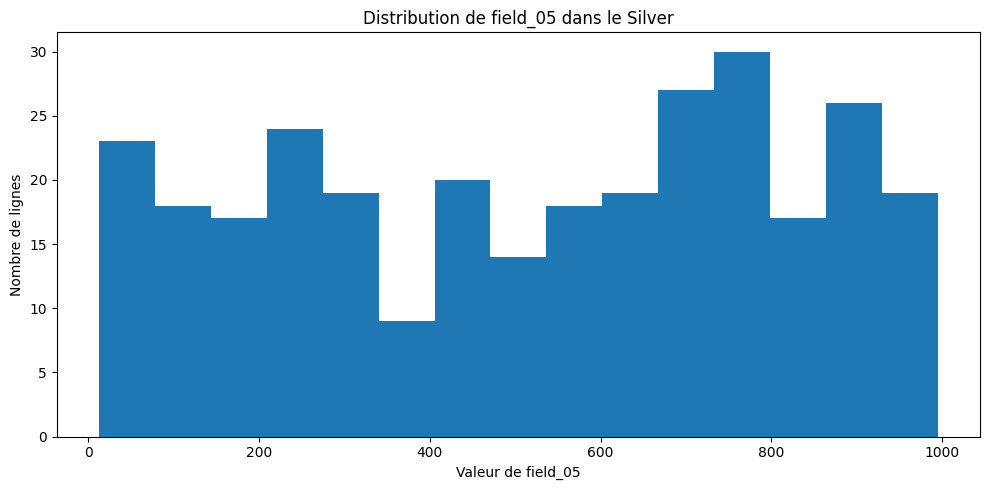

In [5]:
plt.figure(figsize=(10, 5))
plt.bar(by_category['field_07'].astype(str), by_category['promotion_count'])
plt.title('Nombre de promotions par catégorie technique')
plt.xlabel('Catégorie technique field_07')
plt.ylabel('Nombre de lignes')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(out / 'visualizations/promotions_par_categorie.png', dpi=150, bbox_inches='tight')
plt.show()

costs = silver.select('field_05').where(F.col('field_05').isNotNull()).toPandas()
costs.to_csv(out / 'outputs/distribution_field_05.csv', index=False)
plt.figure(figsize=(10, 5))
plt.hist(costs['field_05'], bins=15)
plt.title('Distribution de field_05 dans le Silver')
plt.xlabel('Valeur de field_05')
plt.ylabel('Nombre de lignes')
plt.tight_layout()
plt.savefig(out / 'visualizations/distribution_field_05.png', dpi=150, bbox_inches='tight')
plt.show()